### Simulaciones de trayectorías (plásticos)


## Introducción

Comprender las trayectorias en el océano es importante para varias aplicaciones, como la contaminación marina por plásticos, pero también para otros contaminantes oceánicos como los derrames de petróleo o para estudios de ecología marina para comprender la conectividad de las especies marinas. Las simulaciones Lagrangianas son una  herramienta potente para obtener trayectorias marinas. Una de las herramientas de software abierto que existen es OceanParcels. Usando como entrada campos de velocidad, como los que vimos en el tutorial anterior (por ejemplo, productos altimetría satelital de la superficie del mar), podemos obtener fácilmente trayectorias de partículas con diferentes características.

<!-- Here will look at an example of a Lagrangian simulation..... -->

¿Quieres saber más detalles sobre OceanParcels? Más info. [aquí](https://docs.oceanparcels.org/en/latest/index.html).

Existen también otras herramientas en abierto como [OpenDrift](https://opendrift.github.io/).


También puede explorar el simulador en línea [plastic adrift](https://plasticadrift.org/)

## ¿Cómo funciona?

### Características de la simulación:
* Duración (runtime): 10 días
* Número de partículas: 20 (1 línea longitudinal (norte-sur))

In [1]:
%matplotlib inline

import numpy as np
import math
from datetime import timedelta
from glob import glob
import xarray as xr
from parcels import FieldSet, ParticleSet 
import parcels

import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
from cartopy.mpl.gridliner import LongitudeFormatter, LatitudeFormatter

import warnings
warnings.filterwarnings('ignore')

In [2]:
import parcels
parcels.__version__ # para saber la versión del paquete parcels que estamos usando

'4.0.3'

# Campos de entrada (input fields):

Usaremos los campos de velocidad de derivados de datos de satélite obtenidos de la plataforma [Copernicus Marine Service](https://marine.copernicus.eu/). 

El producto específico es el siguiente: https://data.marine.copernicus.eu/product/SEALEVEL_GLO_PHY_L4_MY_008_047/description

Usamos los datos diarios con resolución espacial de ~1/8˚ (~14 km).

In [3]:
filedir = '/home/jovyan/shared/datos_para_tutoriales/taller_corrientes_y_plasticos_python/'

In [4]:
# Vemos la lista de ficheros que vamos a usar para el tutorial:
!ls /home/jovyan/shared/datos_para_tutoriales/taller_corrientes_y_plasticos_python/

dt_global_allsat_phy_l4_20180901_20241017.nc
dt_global_allsat_phy_l4_20180902_20241017.nc
dt_global_allsat_phy_l4_20180903_20241017.nc
dt_global_allsat_phy_l4_20180904_20241017.nc
dt_global_allsat_phy_l4_20180905_20241017.nc
dt_global_allsat_phy_l4_20180906_20241017.nc
dt_global_allsat_phy_l4_20180907_20241017.nc
dt_global_allsat_phy_l4_20180908_20241017.nc
dt_global_allsat_phy_l4_20180909_20241017.nc
dt_global_allsat_phy_l4_20180910_20241017.nc
dt_global_allsat_phy_l4_20180911_20241017.nc
dt_global_allsat_phy_l4_20180912_20241017.nc
dt_global_allsat_phy_l4_20180913_20241017.nc
dt_global_allsat_phy_l4_20180914_20241017.nc
dt_global_allsat_phy_l4_20180915_20241017.nc


## Primero cargamos un fichero de ejemplo:

In [5]:
ds_m = xr.open_dataset(filedir + "dt_global_allsat_phy_l4_20180906_20241017.nc") 


In [6]:
ds_m

<xarray.Dataset> Size: 332MB
Dimensions:         (latitude: 1440, nv: 2, longitude: 2880, time: 1)
Coordinates:
  * latitude        (latitude) float32 6kB -89.94 -89.81 -89.69 ... 89.81 89.94
  * nv              (nv) int32 8B 0 1
  * longitude       (longitude) float32 12kB -179.9 -179.8 ... 179.8 179.9
  * time            (time) datetime64[ns] 8B 2018-09-06
Data variables: (12/14)
    crs             int32 4B ...
    lat_bnds        (latitude, nv) float32 12kB ...
    lon_bnds        (longitude, nv) float32 23kB ...
    sla             (time, latitude, longitude) float64 33MB ...
    err_sla         (time, latitude, longitude) float64 33MB ...
    ugosa           (time, latitude, longitude) float64 33MB ...
    ...              ...
    err_vgosa       (time, latitude, longitude) float64 33MB ...
    adt             (time, latitude, longitude) float64 33MB ...
    ugos            (time, latitude, longitude) float64 33MB ...
    vgos            (time, latitude, longitude) float64 33MB ...
    flag_ice        (time, latitude, longitude) float64 33MB ...
    tpa_correction  (time) float64 8B ...
Attributes: (12/42)
    Conventions:                     CF-1.6
    Metadata_Conventions:            Unidata Dataset Discovery v1.0
    cdm_data_type:                   Grid
    comment:                         Sea Surface Height measured by Altimetry...
    contact:                         servicedesk.cmems@mercator-ocean.eu
    creator_email:                   servicedesk.cmems@mercator-ocean.eu
    ...                              ...
    geospatial_vertical_units:       m
    time_coverage_duration:          P1D
    time_coverage_resolution:        P1D
    time_coverage_end:               2018-09-06T12:00:00Z
    time_coverage_start:             2018-09-05T12:00:00Z
    platform:                        Cryosat-2, Altika Drifting Phase, Haiyan...

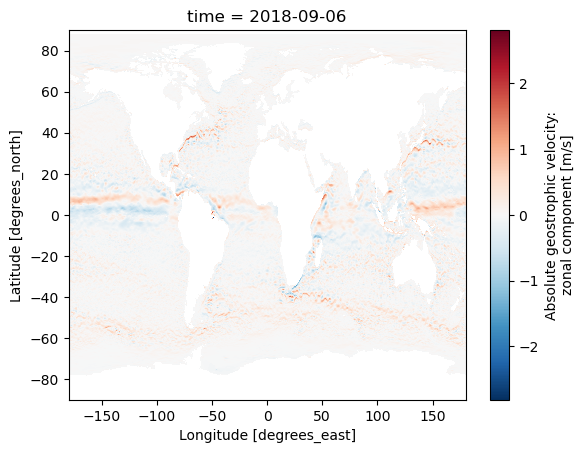

In [7]:
ds_m.ugos[0,:,:].plot()

## Seleccionamos una subzona del Pacífico este:

In [8]:
lon_min = -100
lon_max = -75
lat_min = 2
lat_max = 10

In [9]:
ds_m_sub = ds_m.where((ds_m.longitude<lon_max)&(ds_m.longitude>lon_min)&(ds_m.latitude<lat_max)&(ds_m.latitude>lat_min), drop=True)


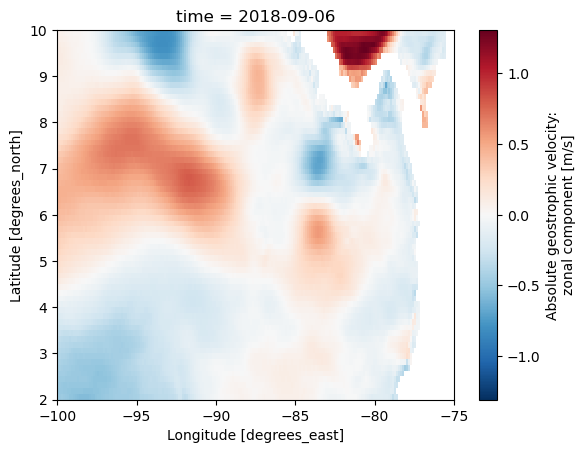

In [10]:
ds_m_sub.ugos[0,:,:].plot()

## Definimos el "fieldset" (campo de velocidad) para las simulaciones:

### Primero indicamos que ficheros usaremos para los campos de velocidad (indicando también el directorio, filedir):

In [11]:
ds = xr.open_mfdataset(filedir + "dt_global_allsat_phy_l4_201809[0-1]?_*.nc") 

"dt_global_allsat_phy_l4_201809[0-1]?_*.nc" para definir la lista de ficheros usamos expresiones regulares ("[0-1]" , "?", "*").  

El uso de estas expresiones regulares nos permite decir que vamos a usar una lista de ficheros.  Todos los ficheros correspondientes a esta expresión los podemos ver si hacemos :

In [12]:
!ls /home/jovyan/shared/datos_para_tutoriales/taller_corrientes_y_plasticos_python/dt_global_allsat_phy_l4_201809[0-1]?_*.nc

/home/jovyan/shared/datos_para_tutoriales/taller_corrientes_y_plasticos_python/dt_global_allsat_phy_l4_20180901_20241017.nc
/home/jovyan/shared/datos_para_tutoriales/taller_corrientes_y_plasticos_python/dt_global_allsat_phy_l4_20180902_20241017.nc
/home/jovyan/shared/datos_para_tutoriales/taller_corrientes_y_plasticos_python/dt_global_allsat_phy_l4_20180903_20241017.nc
/home/jovyan/shared/datos_para_tutoriales/taller_corrientes_y_plasticos_python/dt_global_allsat_phy_l4_20180904_20241017.nc
/home/jovyan/shared/datos_para_tutoriales/taller_corrientes_y_plasticos_python/dt_global_allsat_phy_l4_20180905_20241017.nc
/home/jovyan/shared/datos_para_tutoriales/taller_corrientes_y_plasticos_python/dt_global_allsat_phy_l4_20180906_20241017.nc
/home/jovyan/shared/datos_para_tutoriales/taller_corrientes_y_plasticos_python/dt_global_allsat_phy_l4_20180907_20241017.nc
/home/jovyan/shared/datos_para_tutoriales/taller_corrientes_y_plasticos_python/dt_global_allsat_phy_l4_20180908_20241017.nc
/home/jo

Vemos que nos aparece una lista de ficheros que empiezan todos por "dt_global_allsat_phy_l4_201809" y a continuación siguen por 0 o 1 (la parte de [0-1]) cualquier otro dígito seguido por _ ("?_"), y luego el "*" para decir que cualquier digito a continuación seguido por ".nc" 

Para saber más sobre expresiones regulares pueden usar esta página: https://regex101.com/ . 

### Usamos la velocidad Euleriana, así que elegimos las variables ugos y vgos:

In [13]:
fields = {
    "U": ds["ugos"],
    "V": ds["vgos"]
}

### Adaptamos nuestros datos a las convenciones de malla de Parcels:
Los datos pueden estar definidos en diferentes tipos de malla. La nueva versión de Parcels (v4) utiliza las convenciones SGRID para describir la estructura de estas mallas. Por tanto, necesitamos adaptar nuestros datos a estas convenciones, sin modificar su malla original. Para más información sobre los diferentes tipos de mallas ver [aquí](https://docs.parcels-code.org/en/latest/user_guide/fieldsets_grids.html).

In [14]:
ds_sgrid = parcels.convert.copernicusmarine_to_sgrid(fields=fields) 


INFO: No depth dimension found in dataset. Assuming surface data and adding a singleton depth dimension.


Como usamos datos sol ode superficie, nos sale el mensaje de arriba indicándonos que no tenemos la variable de profundidad (depth).

### Ahora ya tenemos todo los elementos necesarios para definir nuestro _fieldset_ :

In [15]:
fieldset = parcels.FieldSet.from_sgrid_conventions(ds_sgrid)

### Paso extra para aumentar la velocidad de la simulación:
En esta línea convertimos el FieldSet en un "windowed array", para un mejor rendimiento (más rápido). Para más información ver [aquí](http://docs.parcels-code.org/en/latest/user_guide/simulation_performance.html).

In [16]:
fieldset = fieldset.to_windowed_arrays()

# Definimos los parámetros de la simulación:

## ¿Cuántas y dónde queremos lanzar las partículas?

### Opción A) Definimos las longitudes y latitudes.
### Por ejemple, lanzamos las partículas sobre una línea:

In [17]:
lat1D = np.arange(4, 6, .1) # (inicio, fin + incremento, incremento)
lon1D = np.ones_like(lat1D) * -90. # todas las partículas a la misma logitud, -90˚

pset_A = ParticleSet(fieldset=fieldset, pclass=parcels.Particle, x=lon1D, y=lat1D)  
 

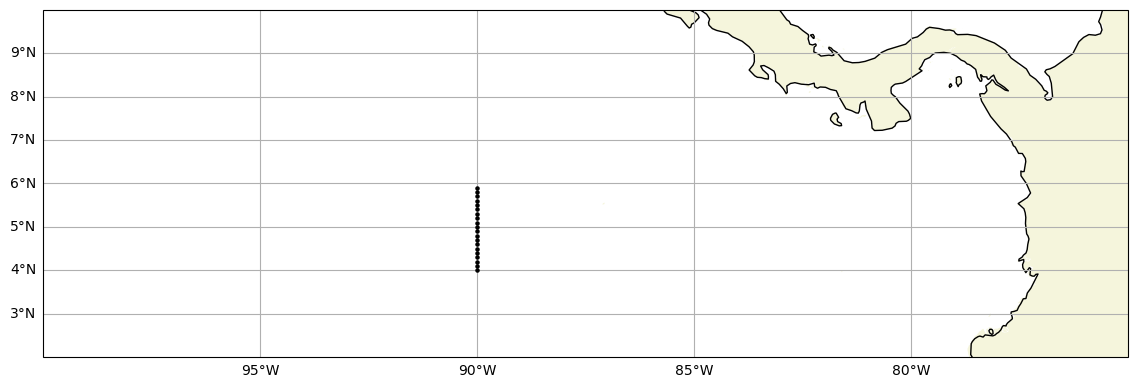

In [18]:
plt.figure(figsize=(14,10))

ax1 = plt.subplot(111, projection=ccrs.PlateCarree())
ax1.coastlines(resolution='50m')
ax1.add_feature(cartopy.feature.LAND, facecolor='beige') # si el codigo tarda mucho, se puede comentar esta línea
ax1.scatter(pset_A.x, pset_A.y, c='k', s=5, transform=ccrs.PlateCarree(), label='Inicio', zorder=20) 
ax1.set_xlim([lon_min, lon_max])
ax1.set_ylim([lat_min, lat_max])
gl = ax1.gridlines(crs=ccrs.PlateCarree(), draw_labels=True)
gl.top_labels = False
gl.right_labels = False
gl.xformatter = LongitudeFormatter()
gl.yformatter = LatitudeFormatter() 


Para la gráfica usamos el paquete _cartopy_ . Esta herramienta fue presentada en talleres anteriores y pueden ver el material [aquí](https://github.com/Intercoonecta/Talleres_intermedios/blob/ohwe24/18-Octubre-2024/datos%20espaciales/datos_espaciales_cartopy.ipynb).

## Otros parámetros:

### Definimos cuanto queremos que dure nuestra simulación, en este caso elegimos 10 días:

In [19]:
runtime_days = 10 # días

## Simulación con set de partículas A:

In [20]:
fichero_salida_A = "lag_simu_pset_A_test01" # definimos el nombre del fichero de salida 

**El valor de dt para la simulación**:
(Schmidt et al., 2021; Rühs, 2023)

Para hacer la advección de partículas, necesitamos definir un paso de tiempo, dt. Este paso de tiempo, cuanto más pequeño, más computacionalmente costoso va a ser el cálculo. Por otra parte, deber ser suficientemente pequeño para que nuestras partículas recorran todos los puntos de mallan que deberían. Es decir, que no sea tan grande que se salte algún punto de malla de nuestros campo de velocidades, y por lo tanto que la partículas se pierda alguna estructura presente importante.

Entonces, para evitar esto, podemos definir un dt mínimo que debería cumplir:
dt < dx / vmax
; dónde: 
* dx es la resolución espacial de nuestros datos de velocidad (en caso de que no sea una malla regular, pues el tamaño de malla más pequeño que tengamos.
* vmax es la velocidad máxima de nuestros datos.

Podemos decidir que para que haya un balance entre tiempo de cálculo, y esta regla a seguir, que las partículas esten como mínimo 2 * dt (dos pasos de tiempo de integración) en un punto de malla. Entonces, podemos calcular nuestro dt como:

dt = dx / 2*vmax

*Referencias*

Schmidt et al., 2021: https://os.copernicus.org/articles/17/1067/2021/


Rühs, 2023: https://github.com/sruehs/IMMERSE_waves/tree/develop-mac 


**Ejemplo para nuestro caso:**

In [21]:
dx = (ds_m_sub.longitude[1].values - ds_m_sub.longitude[0].values) * 110000. # en metros

In [22]:
ds_m_sub.ugos.max()

<xarray.DataArray 'ugos' ()> Size: 8B
array(1.3077)
Attributes:
    grid_mapping:   crs
    long_name:      Absolute geostrophic velocity: zonal component
    standard_name:  surface_geostrophic_eastward_sea_water_velocity
    units:          m/s

In [23]:
ds_m_sub.vgos.max()

<xarray.DataArray 'vgos' ()> Size: 8B
array(0.8024)
Attributes:
    grid_mapping:   crs
    long_name:      Absolute geostrophic velocity: meridian component
    standard_name:  surface_geostrophic_northward_sea_water_velocity
    units:          m/s

In [24]:
# Podemos entonces aproximar nuestra vmax a:
vmax = 1.4 # m/s

In [25]:
dt_s = dx / (2*vmax) # segundos
dt_s

np.float32(4910.7144)

In [26]:
dt_m = dt_s / 60. # mins.
dt_m

np.float32(81.84524)

Entonces, nuestro dt debería ser más pequeño de 82 mins., así que en nuestro caso con 25 mins. estamos dentro, incluso podríamos aumentarlos y hacer la simulación más rápida

### Definimos los kernels:

**¿Qué es un kernel?** 

Tras configurar los datos de entrada y las posiciones y tiempos iniciales de las partículas, debemos especificar qué cálculos realizar con las partículas. Estos cálculos, o integraciones numéricas, los llevará a cabo lo que denominamos una función kernel, que actúa sobre todas las partículas del ```ParticleSet```. El cálculo más habitual es la advección de las partículas a través del campo de velocidad. Parcels incluye varios kernels comunes en ```parcels.kernels```, de entre los cuales utilizaremos el kernel de advección de Runge-Kutta (```parcels.kernels.AdvectionRK4```):

In [27]:
kernels = [parcels.kernels.AdvectionRK4] 


### Definimos el fichero de salida:

En la nueva versión de parcels, los ficheros se guardan en formato "parquet". Este formato es más compacto y más rápido de leer. Más inforamción [aquí](https://docs.parcels-code.org/en/latest/user_guide/gettingstarted_output.html). Para simplificar trabajaremos en otro formato para graficar los datos (ver más abajo).

In [28]:
output_file = parcels.ParticleFile(
    path=fichero_salida_A + ".parquet", 
    outputdt=timedelta(hours=24),
    mode="w"
)

### Corremos la simulación:

In [29]:
pset_A.execute(kernels, 
             runtime=timedelta(days=runtime_days),
             dt=timedelta(minutes=25),
             output_file=output_file)

INFO: Output files are stored in lag_simu_pset_A_test01.parquet
Integration time: 2018-09-10T00:00:00 100%|██████████| [00:12<00:00, 69036.41it/s]


In [30]:
!ls # para ver los nuevos ficheros en nuestro directorio

lag_simu_pset_A_test01.parquet
README.md
simulaciones_trayectorias-plasticos_psetA.ipynb
simulaciones_trayectorias-plasticos_psetA_v4-Copy1.ipynb
simulaciones_trayectorias-plasticos_psetA_v4.ipynb
simulaciones_trayectorias-plasticos_psetB.ipynb


"Si inicia una celda con !, el contenido de esta se ejecuta como un comando bash en el contenedor de su notebook." (fuente: https://enterprise.arcgis.com/es/notebook/latest/use/windows/essential-notebook-commands.htm)

### Convertimos el fichero de salida en un formato leíble por xarray (mismo formato que en la versión 3 de parcels):
Guardamos el fichero en formato .zarr que es equivalente a netcdf (.nc).

**¡Atención! Si el fichero .zarr ya existe, nos dará error.**

In [31]:
parcels.particlefile_to_v3_zarr(   
    fichero_salida_A + ".parquet",
    fichero_salida_A + ".zarr"
)

"Zarr es un formato de datos basado en la nube que mejora el acceso a los datos multidimensionales." (fuente: https://pro.arcgis.com/es/pro-app/latest/help/data/imagery/multidimensional-raster-types.htm)

Mas información aquí: https://www.inta.es/INTA/gl/blogs/copernicus/BlogEntry_1706695503125

In [32]:
!ls # para ver los nuevos ficheros en nuestro directorio

lag_simu_pset_A_test01.parquet
lag_simu_pset_A_test01.zarr
README.md
simulaciones_trayectorias-plasticos_psetA.ipynb
simulaciones_trayectorias-plasticos_psetA_v4-Copy1.ipynb
simulaciones_trayectorias-plasticos_psetA_v4.ipynb
simulaciones_trayectorias-plasticos_psetB.ipynb


# Echemos un vistazo a las trayectorias generadas:

In [33]:
ds = xr.open_dataset("lag_simu_pset_A_test01.zarr", engine="zarr")

In [34]:
ds

<xarray.Dataset> Size: 5kB
Dimensions:     (trajectory: 20, obs: 11)
Coordinates:
  * trajectory  (trajectory) int64 160B 0 1 2 3 4 5 6 7 ... 13 14 15 16 17 18 19
  * obs         (obs) int64 88B 0 1 2 3 4 5 6 7 8 9 10
Data variables:
    lat         (trajectory, obs) float32 880B ...
    lon         (trajectory, obs) float32 880B ...
    time        (trajectory, obs) datetime64[ns] 2kB ...
    z           (trajectory, obs) float32 880B ...
Attributes:
    feature_type:           trajectory
    Conventions:            CF-1.6/CF-1.7
    ncei_template_version:  NCEI_NetCDF_Trajectory_Template_v2.0
    parcels_version:        4.0.3
    parcels_grid_mesh:      SphericalMesh(radius=6366707.019493707)
    parcels_kernels:        AdvectionRK4

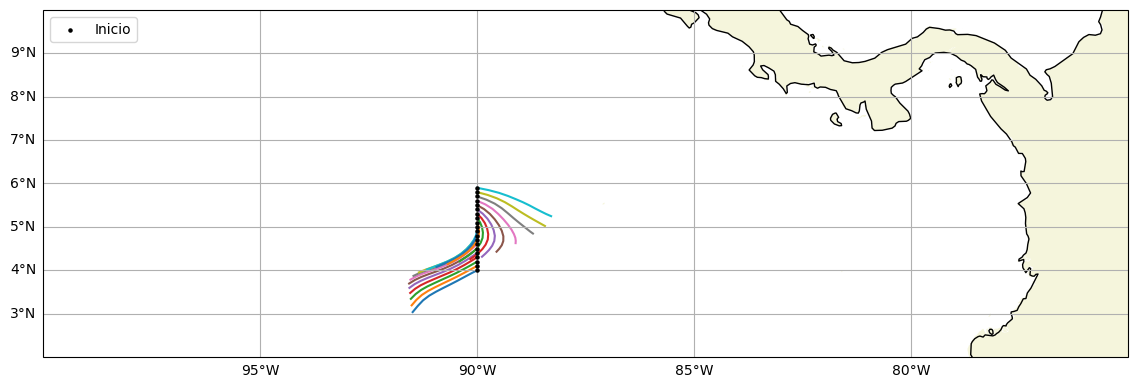

In [35]:
plt.figure(figsize=(14,10))

ax1 = plt.subplot(111, projection=ccrs.PlateCarree())
ax1.coastlines(resolution='50m')
ax1.add_feature(cartopy.feature.LAND, facecolor='beige') # si el codigo tarda mucho, se puede comentar esta línea

# Partículas al inicio:
ax1.scatter(ds['lon'][:,0], ds['lat'][:,0], c='k', s=5, transform=ccrs.PlateCarree(), label='Inicio', zorder=20)

# Trayectorias de las partículas:
ax1.plot(ds['lon'].T, ds['lat'].T, transform=ccrs.PlateCarree())

# Añadimos los límites al mapa:
ax1.set_xlim([lon_min, lon_max])
ax1.set_ylim([lat_min, lat_max])

# Añadimos la leyenda:
ax1.legend(loc=2)

# Gridlines
gl = ax1.gridlines(crs=ccrs.PlateCarree(), draw_labels=True)
gl.top_labels = False
gl.right_labels = False
gl.xformatter = LongitudeFormatter()
gl.yformatter = LatitudeFormatter()


## Graficamos las partículas con los campos de velocidad de fondo:

### Cargamos las velocidades para todos los días:

In [36]:
ficheros = sorted(glob(filedir + "dt_global_allsat_phy_l4_201809[0-1]*.nc"))
ficheros = ficheros[0:10] # sleccionamos los 10 primeros días usado para la simulación
ficheros

['/home/jovyan/shared/datos_para_tutoriales/taller_corrientes_y_plasticos_python/dt_global_allsat_phy_l4_20180901_20241017.nc',
 '/home/jovyan/shared/datos_para_tutoriales/taller_corrientes_y_plasticos_python/dt_global_allsat_phy_l4_20180902_20241017.nc',
 '/home/jovyan/shared/datos_para_tutoriales/taller_corrientes_y_plasticos_python/dt_global_allsat_phy_l4_20180903_20241017.nc',
 '/home/jovyan/shared/datos_para_tutoriales/taller_corrientes_y_plasticos_python/dt_global_allsat_phy_l4_20180904_20241017.nc',
 '/home/jovyan/shared/datos_para_tutoriales/taller_corrientes_y_plasticos_python/dt_global_allsat_phy_l4_20180905_20241017.nc',
 '/home/jovyan/shared/datos_para_tutoriales/taller_corrientes_y_plasticos_python/dt_global_allsat_phy_l4_20180906_20241017.nc',
 '/home/jovyan/shared/datos_para_tutoriales/taller_corrientes_y_plasticos_python/dt_global_allsat_phy_l4_20180907_20241017.nc',
 '/home/jovyan/shared/datos_para_tutoriales/taller_corrientes_y_plasticos_python/dt_global_allsat_phy_l4

In [37]:
ds_m_all = xr.open_mfdataset(ficheros)

### Graficamos en el primer paso de tiempo con la velocidad zonal de fondo:

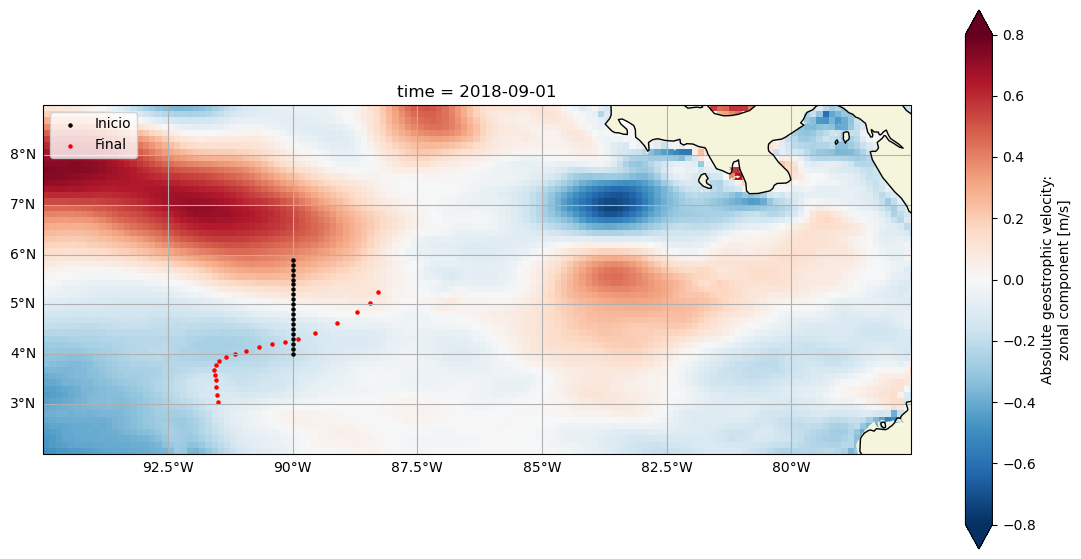

In [38]:
plt.figure(figsize=(14,7))

ax1 = plt.subplot(111, projection=ccrs.PlateCarree())

# Graficamos las velocidades:
ds_m_all.ugos[0,:,:].plot(vmin=-.8, vmax=.8, cmap='RdBu_r', transform=ccrs.PlateCarree(), zorder=1)

# Añadimos la tierra
ax1.coastlines(resolution='50m', zorder=3)
ax1.add_feature(cartopy.feature.LAND, facecolor='beige', zorder=2) # si el codigo tarda mucho, se puede comentar esta línea

# Partículas al inicio 
ax1.scatter(ds['lon'][:,0], ds['lat'][:,0], c='k', s=5, transform=ccrs.PlateCarree(), label='Inicio',zorder=20)
# Partículas al final
ax1.scatter(ds['lon'][:,-1], ds['lat'][:,-1], c='r', s=5, transform=ccrs.PlateCarree(), label='Final')

# Añadimos los límites al mapa:
ax1.set_xlim([-95, -77.6])
ax1.set_ylim([lat_min, 9])

# Añadimos la leyenda:
ax1.legend(loc=2)

# Gridlines:
gl = ax1.gridlines(crs=ccrs.PlateCarree(), draw_labels=True)
gl.top_labels = False
gl.right_labels = False
gl.xformatter = LongitudeFormatter()
gl.yformatter = LatitudeFormatter()


### Graficamos en el último paso de tiempo con la velocidad meridional de fondo:

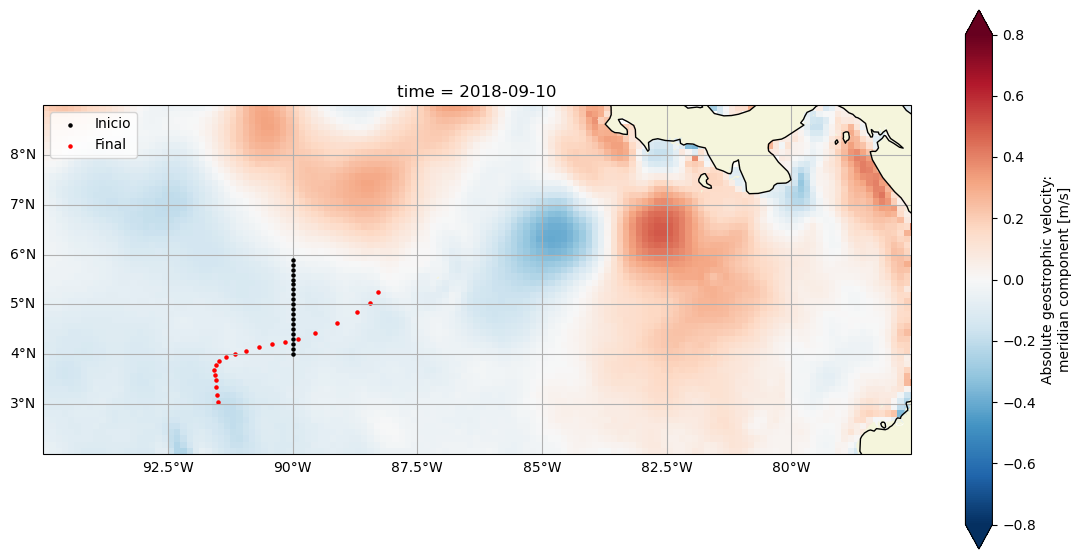

In [39]:
plt.figure(figsize=(14,7))

ax1 = plt.subplot(111, projection=ccrs.PlateCarree())

# Graficamos las velocidades:
ds_m_all.vgos[-1,:,:].plot(vmin=-.8, vmax=.8, cmap='RdBu_r', transform=ccrs.PlateCarree(), zorder=1)

# Añadimos la tierra
ax1.coastlines(resolution='50m', zorder=3)
ax1.add_feature(cartopy.feature.LAND, facecolor='beige', zorder=2) # si el codigo tarda mucho, se puede comentar esta línea

# Partículas al inicio 
ax1.scatter(ds['lon'][:,0], ds['lat'][:,0], c='k', s=5, transform=ccrs.PlateCarree(), label='Inicio',zorder=20)
# Partículas al final
ax1.scatter(ds['lon'][:,-1], ds['lat'][:,-1], c='r', s=5, transform=ccrs.PlateCarree(), label='Final')

# Añadimos los límites al mapa:
ax1.set_xlim([-95, -77.6])
ax1.set_ylim([lat_min, 9])

# Añadimos la leyenda:
ax1.legend(loc=2)

# Gridlines:
gl = ax1.gridlines(crs=ccrs.PlateCarree(), draw_labels=True)
gl.top_labels = False
gl.right_labels = False
gl.xformatter = LongitudeFormatter()
gl.yformatter = LatitudeFormatter()


# Referencias

Laura Gomez-Navarro, & Paul Hargous. (2024). IMEDEA-AP-LAB/MASS24_Altimetry_tutorial: v1.0.0 (v1.0.0). Zenodo. https://doi.org/10.5281/zenodo.13962687

Parcels v4 Quickstart tutorial. https://docs.parcels-code.org/en/latest/user_guide/gettingstarted_quickstart.html